# NumCompute-Stream: learning from data that arrives in chunks

Most textbook examples load a whole dataset, fit a model once, and evaluate it once. Real data often arrives over time instead: sensor readings, transactions, log lines. A streaming model has to learn from each new piece **without going back to the full history**, and must be evaluated honestly as it goes.

This notebook works through the streaming side of NumCompute using the bundled Titanic passenger table. We pretend the 891 rows arrive in chunks of 90 and never look ahead.

**Contents**

1. Setup
2. Reading a CSV as a stream (`io`)
3. Streaming statistics (`stats`, plus `sort_search` and `rank`)
4. Incremental preprocessing (`preprocessing`)
5. A decision tree with buffered retraining (`tree`)
6. Putting it together in a pipeline (`pipeline`)
7. Test-then-train with `StreamTrainer` (`stream`)
8. Streaming metrics in detail (`metrics`)
9. Plotting results (`visualise`)
10. How the buffer size changes the model
11. Benchmarks (`benchmarking`)
12. Summary

All the algorithms live in the `numcompute_stream` package. The notebook only calls them, so every cell can be read as an example of the public API.

*Run the cells from top to bottom. The notebook works whether Jupyter is started in the project root or in `demo/`.*

## 1. Setup

In [36]:
from pathlib import Path
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np

# Find the project root so the package can be imported from either location.
project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "NumCompute" / "numcompute_stream").is_dir()
)
sys.path.insert(0, str(project_root / "NumCompute"))

from numcompute_stream.benchmarking import (
    benchmark_streaming_buffer_sizes,
    benchmark_toolkit,
    format_toolkit_table,
)
from numcompute_stream.io import iter_csv
from numcompute_stream.metrics import (
    AUC, F1, Accuracy, ConfusionMatrix, Precision, Recall, RollingWindowMetric,
    accuracy, confusion_matrix, f1, roc_auc_score,
)
from numcompute_stream.pipeline import FeatureUnion, Pipeline
from numcompute_stream.rank import StreamingRanker
from numcompute_stream.sort_search import StreamingTopK
from numcompute_stream.preprocessing import (
    ColumnSelector, Imputer, MinMaxScaler, OneHotEncoder, StandardScaler,
)
from numcompute_stream.stats import StreamingHistogram, StreamingStats, update_stats
from numcompute_stream.stream import StreamTrainer, deep_sizeof
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.visualise import (
    compare_models, plot_decision_tree, plot_metric_over_time,
    plot_predictions_vs_ground_truth,
)

DATA_PATH = project_root / "demo" / "data" / "titanic.csv"
CHUNK_SIZE = 90
np.set_printoptions(precision=3, suppress=True)

## 2. Reading a CSV as a stream

`iter_csv` reads the file lazily and yields `(header, chunk)` pairs, so only one chunk is held in memory at a time. Because the Titanic table mixes numbers and text, each chunk comes back as an object array. Blank cells are filled with `NaN`.

In [37]:
chunks = []
for header, chunk in iter_csv(DATA_PATH, chunksize=CHUNK_SIZE):
    chunks.append(chunk)

column = {name: index for index, name in enumerate(header)}
print(f"{len(chunks)} chunks, sizes: {[len(chunk) for chunk in chunks]}")
print("Columns:", ", ".join(header))
print("\nFirst three rows of the first chunk:")
for row in chunks[0][:3]:
    print({name: row[column[name]] for name in ("survived", "pclass", "sex", "age", "fare", "embarked")})

10 chunks, sizes: [90, 90, 90, 90, 90, 90, 90, 90, 90, 81]
Columns: survived, pclass, sex, age, sibsp, parch, fare, embarked, class, who, adult_male, deck, embark_town, alive, alone

First three rows of the first chunk:
{'survived': 0.0, 'pclass': 3.0, 'sex': 'male', 'age': 22.0, 'fare': 7.25, 'embarked': 'S'}
{'survived': 1.0, 'pclass': 1.0, 'sex': 'female', 'age': 38.0, 'fare': 71.2833, 'embarked': 'C'}
{'survived': 1.0, 'pclass': 3.0, 'sex': 'female', 'age': 26.0, 'fare': 7.925, 'embarked': 'S'}


The label we want to predict is `survived` (1 = survived). Each stream item is a pair `(features, labels)`. Missing ages are common, which is why imputation matters later.

In [38]:
stream = [(chunk, chunk[:, column["survived"]].astype(float).astype(int)) for chunk in chunks]

missing_age = [int(np.isnan(X[:, column["age"]].astype(float)).sum()) for X, _ in stream]
survival_rate = [float(y.mean()) for _, y in stream]
print("Missing ages per chunk:  ", missing_age)
print("Survival rate per chunk: ", np.round(survival_rate, 2))

Missing ages per chunk:   [21, 14, 17, 20, 16, 24, 20, 16, 15, 14]
Survival rate per chunk:  [0.43 0.22 0.4  0.5  0.43 0.34 0.41 0.38 0.36 0.36]


### 2.1 Target balance and age distribution

Before training, compare survival rates across passenger class and sex, and inspect how observed ages differ by outcome. The bars include sample counts because small groups can produce unstable rates; the age histogram excludes missing ages.

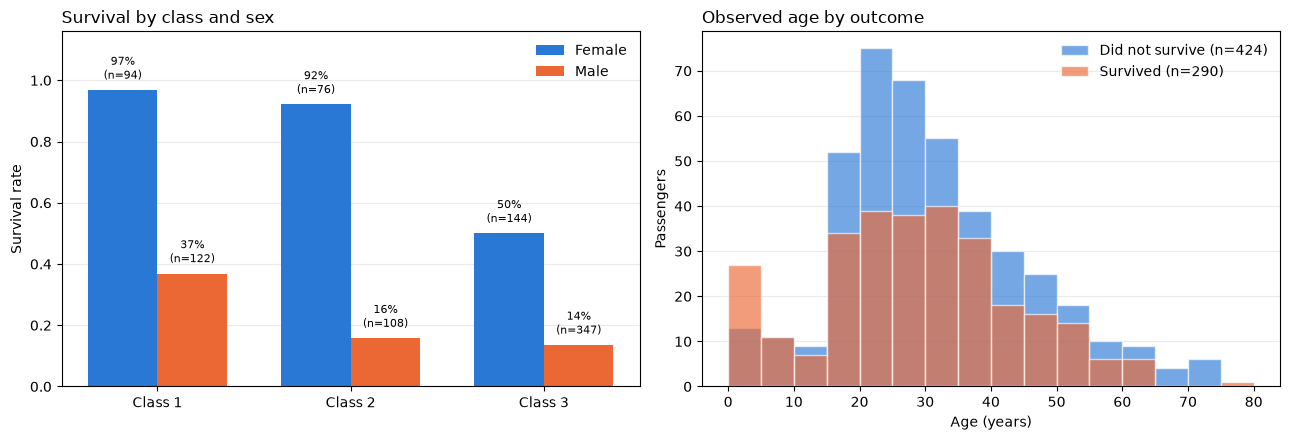

In [39]:
eda_table = np.concatenate([X for X, _ in stream])
eda_labels = np.concatenate([y for _, y in stream])
pclass = eda_table[:, column["pclass"]].astype(int)
sex = eda_table[:, column["sex"]].astype(str)
ages = eda_table[:, column["age"]].astype(float)

figure, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
classes = (1, 2, 3)
x = np.arange(len(classes))
width = 0.36
for offset, group, color in ((-width / 2, "female", "#2a78d6"),
                             (width / 2, "male", "#eb6834")):
    rates, sizes = [], []
    for passenger_class in classes:
        mask = (pclass == passenger_class) & (sex == group)
        sizes.append(int(mask.sum()))
        rates.append(float(eda_labels[mask].mean()) if sizes[-1] else 0.0)
    bars = left.bar(x + offset, rates, width, label=group.title(), color=color)
    for bar, rate, size in zip(bars, rates, sizes):
        left.text(bar.get_x() + bar.get_width() / 2, rate + 0.025,
                  f"{rate:.0%}\n(n={size})", ha="center", va="bottom", fontsize=8)
left.set_xticks(x, [f"Class {value}" for value in classes])
left.set_ylim(0, 1.16)
left.set_ylabel("Survival rate")
left.set_title("Survival by class and sex", loc="left")
left.legend(frameon=False)
left.grid(axis="y", alpha=0.25)
left.set_axisbelow(True)

for survived, label, color in ((0, "Did not survive", "#2a78d6"),
                               (1, "Survived", "#eb6834")):
    observed = ages[(eda_labels == survived) & np.isfinite(ages)]
    right.hist(observed, bins=np.arange(0, 81, 5), alpha=0.65, color=color,
               edgecolor="white", label=f"{label} (n={observed.size})")
right.set_xlabel("Age (years)")
right.set_ylabel("Passengers")
right.set_title("Observed age by outcome", loc="left")
right.legend(frameon=False)
right.grid(axis="y", alpha=0.25)
right.set_axisbelow(True)
figure.tight_layout()
plt.show()

## 3. Streaming statistics

`StreamingStats` updates its summary with each chunk instead of storing the data:

| Statistic | How it is updated | Memory |
|---|---|---|
| count, mean, variance, min, max | parallel Welford merge (numerically stable) | constant per feature |
| quantiles | uniform reservoir sample, exact until the reservoir fills | bounded |
| histogram | fixed number of bins; the range doubles when needed and bin pairs merge, so counts stay exact | constant |

A chunk can be 1D (one feature) or 2D (one statistic per column). `skipna=True` ignores missing values.

### 3.1 Per-feature summary of `age` and `fare`

We stream both columns and then compare against a one-off calculation on the full table, to check that nothing was lost.

In [40]:
age_fare = StreamingStats(bins=8, quantiles=[0.25, 0.5, 0.75], skipna=True)
for X_chunk, _ in stream:
    age_fare.update(X_chunk[:, [column["age"], column["fare"]]].astype(float))

summary = age_fare.result()
full_table = np.concatenate([X for X, _ in stream])
batch = full_table[:, [column["age"], column["fare"]]].astype(float)

print(f"{'feature':<8}{'count':>7}{'mean':>10}{'batch mean':>12}{'std':>9}{'batch std':>11}{'median':>8}")
for index, name in enumerate(["age", "fare"]):
    print(
        f"{name:<8}{summary['count'][index]:>7}{summary['mean'][index]:>10.3f}"
        f"{np.nanmean(batch[:, index]):>12.3f}{summary['std'][index]:>9.3f}"
        f"{np.nanstd(batch[:, index]):>11.3f}{summary['quantiles'][1, index]:>8.1f}"
    )
print("\nQuantiles exact?", summary["quantiles_exact"], "| rows seen:", summary["n_rows"])

feature   count      mean  batch mean      std  batch std  median
age         714    29.699      29.699   14.516     14.516    28.0
fare        891    32.204      32.204   49.666     49.666    14.5

Quantiles exact? True | rows seen: 891


The streamed values match the batch values exactly, and the quantiles are exact because the stream (891 rows) is smaller than the default reservoir (10,000 rows).

### 3.2 The functional API: `update_stats`

`update_stats(chunk, state)` does the same thing as a function call. Pass `None` (or nothing) for the first chunk and keep passing the returned state back in. The state also supports dictionary-style access.

In [41]:
state = None
for X_chunk, _ in stream:
    state = update_stats(X_chunk[:, column["fare"]].astype(float), state, bins=6)

print("count:", state["count"], " mean:", round(state["mean"], 3), " std:", round(state["std"], 3))
print("min/max:", state["min"], "/", state["max"])
print("histogram:", state["histogram"])
print("bin edges:", np.round(state["bin_edges"], 1))

count: 891  mean: 32.204  std: 49.666
min/max: 0.0 / 512.3292
histogram: [836  52   0   3   0   0]
bin edges: [-78.   92.5 263.  433.5 604.  774.6 945.1]


### 3.3 Histograms: adaptive range vs fixed range

With no range given, the histogram starts from the first chunk's range and widens by doubling when later data falls outside it. Counts stay exact, but some bins may end up empty. If you know the range in advance, pass `range=` for the best resolution. Values outside a fixed range are counted separately rather than silently dropped.

In [42]:
adaptive = StreamingHistogram(bins=8)
fixed = StreamingHistogram(bins=8, range=(0, 80))
for X_chunk, _ in stream:
    ages = X_chunk[:, column["age"]].astype(float)
    ages = ages[~np.isnan(ages)]
    adaptive.update(ages)
    fixed.update(ages)

print("adaptive edges:", np.round(adaptive.edges, 1))
print("adaptive counts:", adaptive.counts)
print("fixed edges:   ", np.round(fixed.edges, 1))
print("fixed counts:  ", fixed.counts, "| outside range:", fixed.n_out_of_range_)

adaptive edges: [-31.8   0.8  33.4  66.   98.6 131.2 163.8 196.3 228.9]
adaptive counts: [  4 459 243   8   0   0   0   0]
fixed edges:    [ 0. 10. 20. 30. 40. 50. 60. 70. 80.]
fixed counts:   [ 62 102 220 167  89  48  19   7] | outside range: 0


### 3.4 Sliding window: spotting change over time

With `window_size`, statistics cover only the most recent rows. Here we track the mean fare of the last 180 passengers after each chunk. A cumulative mean would hide local changes; the window shows them.

In [43]:
window = StreamingStats(window_size=180)
cumulative = StreamingStats()
for X_chunk, _ in stream:
    fares = X_chunk[:, column["fare"]].astype(float)
    window.update(fares)
    cumulative.update(fares)
    print(f"rows seen {cumulative['n_rows']:>3}: last-180 mean fare {window['mean']:6.2f} "
          f"| cumulative mean {cumulative['mean']:6.2f}")

rows seen  90: last-180 mean fare  29.91 | cumulative mean  29.91
rows seen 180: last-180 mean fare  27.45 | cumulative mean  27.45
rows seen 270: last-180 mean fare  29.05 | cumulative mean  29.33
rows seen 360: last-180 mean fare  37.57 | cumulative mean  32.51
rows seen 450: last-180 mean fare  37.03 | cumulative mean  32.41
rows seen 540: last-180 mean fare  30.49 | cumulative mean  31.84
rows seen 630: last-180 mean fare  29.68 | cumulative mean  31.63
rows seen 720: last-180 mean fare  34.99 | cumulative mean  32.63
rows seen 810: last-180 mean fare  37.55 | cumulative mean  32.95
rows seen 891: last-180 mean fare  30.97 | cumulative mean  32.20


### 3.5 Streaming top-k and percentile ranks

Two smaller helpers follow the same chunk-by-chunk pattern:

* `StreamingTopK.update(chunk)` keeps only the k best values seen so far (constant memory), with their positions in the stream.
* `StreamingRanker.partial_fit(chunk)` keeps the values sorted as they arrive, so it can answer "what is the 90th percentile?" or "what percentile is this fare?" at any point.

In [44]:
top_fares = StreamingTopK(k=5)
fare_ranker = StreamingRanker()
for X_chunk, _ in stream:
    fares = X_chunk[:, column["fare"]].astype(float)
    top_fares.update(fares)
    fare_ranker.partial_fit(fares)

values, positions = top_fares.result(return_indices=True)
print("5 highest fares:", values, "at stream rows", positions)
print(f"90th percentile fare: {fare_ranker.percentile(90):.2f}")
print("percentile rank of fares 10, 30 and 100:", np.round(fare_ranker.percentile_rank([10, 30, 100]), 1))

5 highest fares: [512.329 512.329 512.329 263.    263.   ] at stream rows [258 679 737  27  88]
90th percentile fare: 77.96
percentile rank of fares 10, 30 and 100: [37.7 73.4 94.1]


## 4. Incremental preprocessing

Every preprocessor has `fit`, `transform` and **`partial_fit`**. They accept a single feature `(n_samples,)` or a matrix `(n_samples, n_features)`, and each column keeps its own learned values.

### 4.1 `StandardScaler`: streamed vs batch

The streamed scaler merges each chunk into a running mean and variance. After all chunks it should match a scaler fitted on everything at once.

In [45]:
numeric_columns = [column[name] for name in ("pclass", "sibsp", "parch", "fare")]
streamed_scaler = StandardScaler()
for X_chunk, _ in stream:
    streamed_scaler.partial_fit(X_chunk[:, numeric_columns].astype(float))

batch_scaler = StandardScaler().fit(full_table[:, numeric_columns].astype(float))
print("streamed mean:", streamed_scaler.mean_)
print("batch mean:   ", batch_scaler.mean_)
print("streamed var: ", streamed_scaler.var_)
print("same result?  ", np.allclose(streamed_scaler.var_, batch_scaler.var_))

streamed mean: [ 2.309  0.523  0.382 32.204]
batch mean:    [ 2.309  0.523  0.382 32.204]
streamed var:  [   0.698    1.215    0.649 2466.665]
same result?   True


`ema_alpha` switches to an exponential moving average, which gives recent chunks more weight. This is useful when the data drifts. In this toy example the values jump from 0 to 10 after 100 samples:

In [46]:
exact, moving = StandardScaler(), StandardScaler(ema_alpha=0.5)
for scaler in (exact, moving):
    scaler.partial_fit(np.zeros(100))
    scaler.partial_fit(np.full(10, 10.0))
print(f"exact mean {exact.mean_:.2f} (all samples weighted equally)")
print(f"EMA mean   {moving.mean_:.2f} (the latest chunk gets weight 0.5)")

exact mean 0.91 (all samples weighted equally)
EMA mean   5.00 (the latest chunk gets weight 0.5)


### 4.2 `MinMaxScaler` and values outside the seen range

In a stream, a later value can fall outside the minimum and maximum seen so far. By default it maps outside `[0, 1]`; `clip=True` keeps outputs inside the range.

In [47]:
first_fares = stream[0][0][:, column["fare"]].astype(float)
scaler = MinMaxScaler().partial_fit(first_fares)
clipping = MinMaxScaler(clip=True).partial_fit(first_fares)
new_values = np.array([0.0, first_fares.max(), 2 * first_fares.max()])
print("seen range:", scaler.data_min_, "to", scaler.data_max_)
print("unclipped:", scaler.transform(new_values))
print("clipped:  ", clipping.transform(new_values))

seen range: 7.225 to 263.0
unclipped: [-0.028  1.     2.028]
clipped:   [0. 1. 1.]


### 4.3 `Imputer`: replacement values that improve over time

The median imputer learns the median age from the observed values seen so far. The mean imputer keeps only a count and a running mean, so its memory does not grow.

In [48]:
age_imputer = Imputer(strategy="median")
for number, (X_chunk, _) in enumerate(stream, start=1):
    age_imputer.partial_fit(X_chunk[:, column["age"]].astype(float))
    if number in (1, 2, 5, 10):
        print(f"after chunk {number:>2}: fill missing ages with {age_imputer.statistics_:.1f}")

example = np.array([22.0, np.nan, 54.0])
print("\ntransform", example, "->", age_imputer.transform(example))

after chunk  1: fill missing ages with 26.0
after chunk  2: fill missing ages with 26.0
after chunk  5: fill missing ages with 28.0
after chunk 10: fill missing ages with 28.0

transform [22. nan 54.] -> [22. 28. 54.]


### 4.4 `OneHotEncoder`: new categories during the stream

When a chunk contains a category not seen before, `partial_fit` adds a new column **at the end**, so existing columns keep their meaning. With `handle_unknown="ignore"`, an unseen category becomes an all-zero row instead of an error. That matters in test-then-train, where we predict on a chunk *before* learning from it.

In [49]:
encoder = OneHotEncoder(handle_unknown="ignore")
encoder.partial_fit(np.array(["S", "C"]))
print("categories:", encoder.unique_categories_)
print(encoder.transform(np.array(["S", "Q"])), "<- 'Q' is unknown, so its row is all zeros")

encoder.partial_fit(np.array(["Q"]))
print("\ncategories:", encoder.unique_categories_, "<- 'Q' added as the last column")
print(encoder.transform(np.array(["S", "Q"])))

categories: ['C' 'S']
[[0. 1.]
 [0. 0.]] <- 'Q' is unknown, so its row is all zeros

categories: ['C' 'S' 'Q'] <- 'Q' added as the last column
[[0. 1. 0.]
 [0. 0. 1.]]


## 5. A decision tree with buffered retraining

`DecisionTreeClassifier` is a depth-limited CART tree using Gini impurity (or `criterion="entropy"`). For each node it sorts each feature once and scores every possible threshold together using running class counts.

A tree cannot easily be updated one sample at a time, so `partial_fit` uses **buffered retraining**:

1. each chunk is added to a buffer;
2. once the buffer holds at least `buffer_size` samples, a new tree is trained on the buffer and the buffer is cleared;
3. between retrains, `predict` keeps using the last trained tree.

The table shows this happening with `buffer_size=200` and chunks of 90.

In [50]:
simple_features = [column[name] for name in ("pclass", "sibsp", "parch", "fare")]
tree = DecisionTreeClassifier(max_depth=4, buffer_size=200)

print(f"{'chunk':>5} {'buffered':>9} {'retrains':>9} {'fitted':>7}")
for number, (X_chunk, y_chunk) in enumerate(stream, start=1):
    tree.partial_fit(X_chunk[:, simple_features].astype(float), y_chunk)
    print(f"{number:>5} {tree.buffered_samples:>9} {tree.retrain_count_:>9} {str(tree.is_fitted):>7}")

print(f"\nfinal tree: depth {tree.depth_}, {tree.n_leaves_} leaves, classes {tree.classes_}")

chunk  buffered  retrains  fitted
    1        90         0   False
    2       180         0   False
    3         0         1    True
    4        90         1    True
    5       180         1    True
    6         0         2    True
    7        90         2    True
    8       180         2    True
    9         0         3    True
   10        81         3    True

final tree: depth 4, 12 leaves, classes [0 1]


Retraining happens after chunks 3, 6 and 9 (270 buffered samples each time, since a whole chunk is always added before checking). The last chunk stays in the buffer until more data arrives.

Besides hard predictions, the tree gives class probabilities: the share of each class among the training samples in the leaf a passenger reaches.

In [51]:
X_example = stream[-1][0][:5, simple_features].astype(float)
print("features (pclass, sibsp, parch, fare):\n", X_example)
print("P(died), P(survived):\n", tree.predict_proba(X_example))
print("prediction:", tree.predict(X_example))

features (pclass, sibsp, parch, fare):
 [[ 3.     0.     0.     7.888]
 [ 3.     0.     0.    24.15 ]
 [ 2.     0.     0.    10.5  ]
 [ 3.     4.     2.    31.275]
 [ 3.     0.     0.     8.05 ]]
P(died), P(survived):
 [[0.818 0.182]
 [1.    0.   ]
 [0.714 0.286]
 [1.    0.   ]
 [0.818 0.182]]
prediction: [0 0 0 0 0]


### 5.1 Visualising the fitted tree

This diagram shows the actual tree last trained by the streaming model (on its most recent 270-row buffer), not a tree retrained on the full history. Each split sends values at or below its threshold left; node colour shows the majority class, and labels report sample counts for each class.

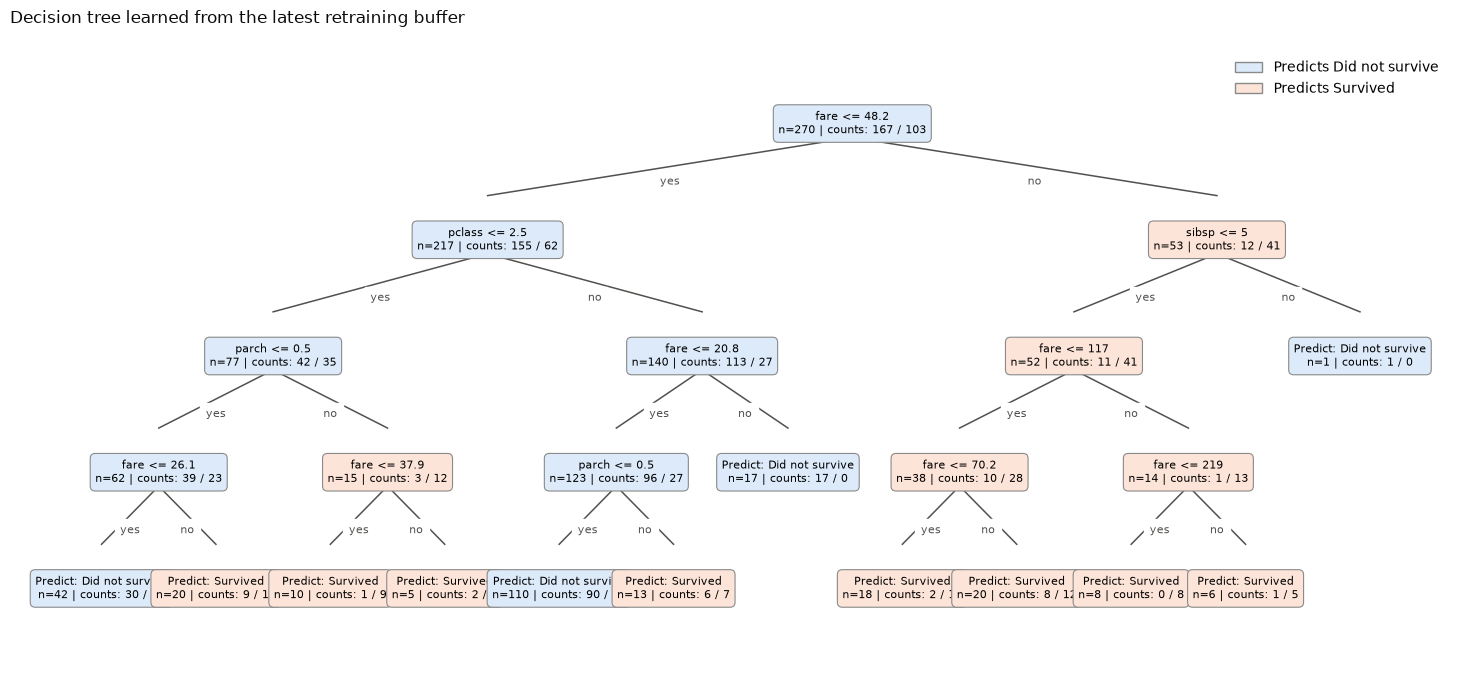

In [52]:
plot_decision_tree(
    tree,
    feature_names=("pclass", "sibsp", "parch", "fare"),
    class_names=("Did not survive", "Survived"),
    title="Decision tree learned from the latest retraining buffer",
);

## 6. Putting it together in a pipeline

The full table has numeric and text columns, so they need different preprocessing. A `FeatureUnion` sends the same rows through two branches and joins the results side by side:

* **numeric**: pick `pclass, age, sibsp, parch, fare` → fill missing values with the median → standardise
* **categorical**: pick `sex, embarked` → one-hot encode (unknown categories ignored)

The tree comes last. Calling `partial_fit` on the outer `Pipeline` updates every step in order with the chunk, then passes the transformed chunk to the tree's own `partial_fit`, so buffering still works.

In [53]:
NUMERIC = [column[name] for name in ("pclass", "age", "sibsp", "parch", "fare")]
CATEGORICAL = [column[name] for name in ("sex", "embarked")]


def make_pipeline(buffer_size):
    features = FeatureUnion([
        ("numeric", Pipeline([
            ("select", ColumnSelector(NUMERIC, dtype=float)),
            ("impute", Imputer(strategy="median")),
            ("scale", StandardScaler()),
        ])),
        ("categorical", Pipeline([
            ("select", ColumnSelector(CATEGORICAL)),
            ("encode", OneHotEncoder(handle_unknown="ignore")),
        ])),
    ])
    tree = DecisionTreeClassifier(max_depth=5, min_samples_split=10, buffer_size=buffer_size)
    return Pipeline([("features", features), ("tree", tree)])


pipeline = make_pipeline(buffer_size=180)
pipeline_log = []
print(f"{'chunk':>5} {'buffered':>9} {'retrains':>9} {'accuracy':>9} {'error':>6}")
for number, (X_chunk, y_chunk) in enumerate(stream, start=1):
    # Test first: score the chunk with the model as it is now (if one exists yet) ...
    if pipeline.is_fitted:
        chunk_accuracy = accuracy(y_chunk, pipeline.predict(X_chunk))
        pipeline_log.append({"chunk": number, "accuracy": chunk_accuracy, "error": 1 - chunk_accuracy})
    # ... then train: every step of the pipeline learns from this chunk.
    pipeline.partial_fit(X_chunk, y_chunk)

    tree_step = pipeline.named_steps["tree"]
    scored = pipeline_log[-1] if pipeline_log and pipeline_log[-1]["chunk"] == number else None
    print(f"{number:>5} {tree_step.buffered_samples:>9} {tree_step.retrain_count_:>9} "
          + (f"{scored['accuracy']:>9.3f} {scored['error']:>6.3f}" if scored else f"{'-':>9} {'-':>6}"))

chunk  buffered  retrains  accuracy  error
    1        90         0         -      -
    2         0         1         -      -
    3        90         1     0.733  0.267
    4         0         2     0.856  0.144
    5        90         2     0.767  0.233
    6         0         3     0.856  0.144
    7        90         3     0.767  0.233
    8         0         4     0.711  0.289
    9        90         4     0.778  0.222
   10       171         4     0.852  0.148


Each call to `pipeline.partial_fit(X_chunk, y_chunk)` updates the imputer, scaler and encoder with the chunk, transforms it, and passes it to the tree's own `partial_fit`. The tree buffers it and retrains every second chunk (180 samples). Chunks 1 and 2 are not scored: the first tree is only trained at the end of chunk 2, so before that there is no model to test.

Here is what the tree actually receives: 5 scaled numeric columns followed by the one-hot columns for `sex` and `embarked`.

In [54]:
transformed = pipeline.transform(stream[0][0][:3])
print("transformed shape:", transformed.shape)
print(transformed)

transformed shape: (3, 11)
[[ 0.827 -0.559  0.433 -0.474 -0.502  0.     1.     0.     0.     0.
   1.   ]
 [-1.566  0.669  0.433 -0.474  0.787  1.     0.     1.     0.     0.
   0.   ]
 [ 0.827 -0.252 -0.475 -0.474 -0.489  1.     0.     0.     0.     0.
   1.   ]]


Accuracy and error per chunk, plotted with `visualise.plot_metric_over_time`:

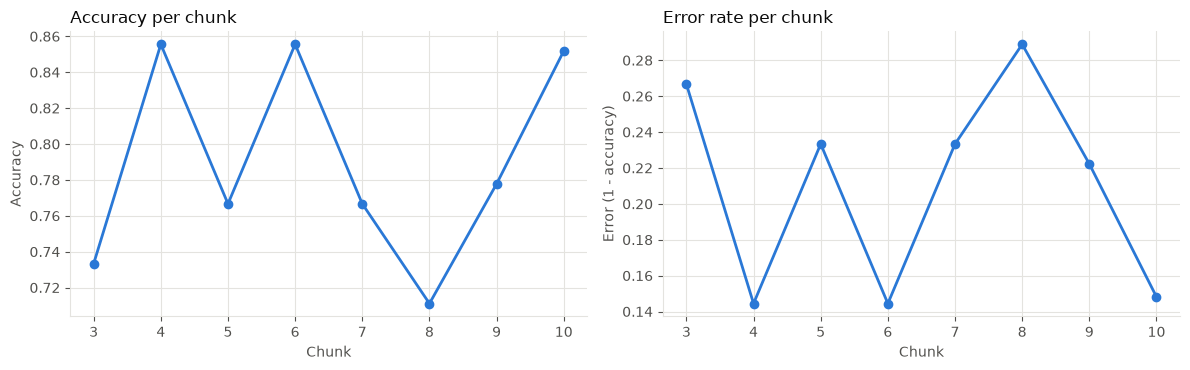

In [55]:
pipeline_chunks = [entry["chunk"] for entry in pipeline_log]
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8))
plot_metric_over_time([entry["accuracy"] for entry in pipeline_log], "Accuracy per chunk",
                      "Accuracy", x_values=pipeline_chunks, ax=left, show=False)
plot_metric_over_time([entry["error"] for entry in pipeline_log], "Error rate per chunk",
                      "Error (1 - accuracy)", x_values=pipeline_chunks, ax=right, show=False)
figure.tight_layout()
plt.show()

## 7. Test-then-train with `StreamTrainer`

Section 6 wrote the test-then-train loop by hand. `StreamTrainer` packages that loop: `fit_chunk(X, y)` calls the pipeline's `partial_fit`, `score_chunk(X, y)` evaluates and logs, and `run` does both for every chunk. It also manages the metrics and the log. Its `run` method uses **prequential (test-then-train) evaluation**: each chunk is first used to *score* the current model and only then to *train* it. No chunk is ever scored by a model that has already learned from it, so the accuracy is an honest estimate.

Besides accuracy (always logged), we ask for:

* `F1` for the "survived" class,
* `AUC`, which needs probabilities, so the trainer calls `predict_proba` automatically,
* a `RollingWindowMetric` with the accuracy over the last 3 scored chunks,
* the cumulative `ConfusionMatrix`.

Every metric is logged twice: under its own name for **the current chunk only**, and as `cumulative_<name>` for **everything accumulated so far**. For the rolling metric, "accumulated so far" means "within the window", so its useful value is `cumulative_rolling_accuracy`.

In [56]:
def make_trainer(buffer_size):
    return StreamTrainer(
        make_pipeline(buffer_size),
        metrics={
            "f1": F1(),
            "auc": AUC(),
            "rolling_accuracy": RollingWindowMetric(Accuracy(), window_size=3),
            "confusion": ConfusionMatrix(labels=[0, 1]),
        },
    )


trainer = make_trainer(buffer_size=90)
records = trainer.run(stream)
print(f"scored {len(records)} of {len(stream)} chunks "
      "(no model exists yet when the first chunk arrives, so it is only used for training)")
print(f"cumulative accuracy: {trainer.cumulative_accuracy:.3f}")

scored 9 of 10 chunks (no model exists yet when the first chunk arrives, so it is only used for training)
cumulative accuracy: 0.764


Each scored chunk adds one record to the log, containing chunk and cumulative metrics, the number of samples trained so far, how long training and prediction took, and the model's memory footprint.

In [57]:
print(f"{'chunk':>5} {'trained':>8} {'acc':>6} {'cum acc':>8} {'f1':>6} {'auc':>6} "
      f"{'last 3':>9} {'fit ms':>7} {'memory KB':>10}")
for record in trainer.logs:
    print(
        f"{record['chunk']:>5} {record['samples_trained']:>8} {record['accuracy']:>6.3f} "
        f"{record['cumulative_accuracy']:>8.3f} {record['f1']:>6.3f} {record['auc']:>6.3f} "
        f"{record['cumulative_rolling_accuracy']:>9.3f} {record['fit_seconds'] * 1000:>7.2f} "
        f"{record['memory_bytes'] / 1024:>10.1f}"
    )

chunk  trained    acc  cum acc     f1    auc    last 3  fit ms  memory KB
    2       90  0.844    0.844  0.667  0.775     0.844    3.77       23.6
    3      180  0.700    0.772  0.509  0.667     0.772    1.69       27.0
    4      270  0.789    0.778  0.759  0.820     0.778    1.70       30.6
    5      360  0.800    0.783  0.750  0.772     0.763    1.69       34.0
    6      450  0.722    0.771  0.648  0.800     0.770    1.94       37.8
    7      540  0.767    0.770  0.677  0.796     0.763    1.64       40.7
    8      630  0.733    0.765  0.684  0.784     0.741    1.83       44.5
    9      720  0.711    0.758  0.567  0.685     0.737    2.35       47.9
   10      810  0.815    0.764  0.727  0.787     0.751    1.61       50.5


In [58]:
final = trainer.logs[-1]
print("Cumulative confusion matrix (rows: actual died/survived, columns: predicted):")
print(final["cumulative_confusion"])
print(f"\ncumulative F1 {final['cumulative_f1']:.3f}, cumulative AUC {final['cumulative_auc']:.3f}")
print(f"current model memory: {deep_sizeof(trainer.model) / 1024:.1f} KB")

Cumulative confusion matrix (rows: actual died/survived, columns: predicted):
[[419  79]
 [110 193]]

cumulative F1 0.671, cumulative AUC 0.766
current model memory: 61.4 KB


### 8.1 Cumulative confusion matrix

Counts show how many test-then-train predictions fell into each outcome; row-normalised values make the error pattern comparable across the unequal class sizes.

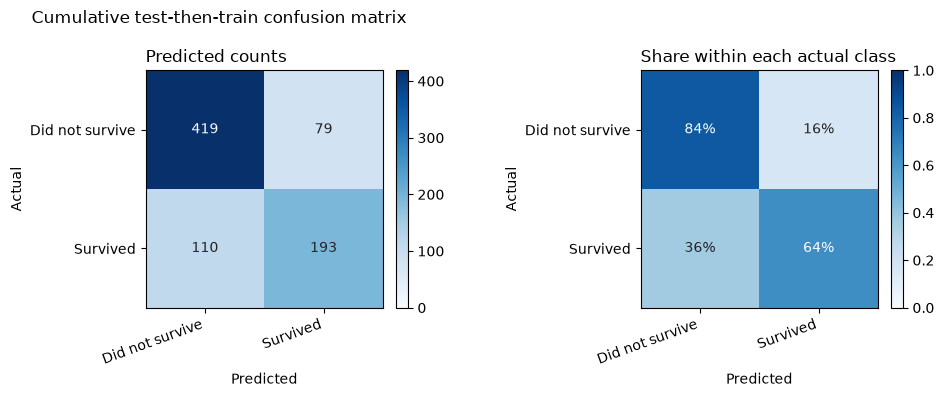

In [59]:
cm = np.asarray(final["cumulative_confusion"])
row_totals = cm.sum(axis=1, keepdims=True)
row_rates = np.divide(cm, row_totals, out=np.zeros_like(cm, dtype=float),
                      where=row_totals != 0)
class_labels = ("Did not survive", "Survived")
figure, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, values, title, fmt, vmax in (
    (axes[0], cm, "Predicted counts", "d", max(1, int(cm.max()))),
    (axes[1], row_rates, "Share within each actual class", ".0%", 1.0),
):
    image = ax.imshow(values, cmap="Blues", vmin=0, vmax=vmax)
    ax.set_xticks(range(2), class_labels, rotation=20, ha="right")
    ax.set_yticks(range(2), class_labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title, loc="left")
    for row in range(2):
        for col in range(2):
            text = format(values[row, col], fmt)
            ax.text(col, row, text, ha="center", va="center",
                    color="white" if values[row, col] > vmax * 0.55 else "#222222")
    figure.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
figure.suptitle("Cumulative test-then-train confusion matrix", x=0.08, ha="left")
figure.tight_layout()
plt.show()

`metric_history(name)` pulls one column out of the log as an array, ready for plotting or further analysis.

In [60]:
print("chunks:  ", trainer.metric_history("chunk"))
print("accuracy:", trainer.metric_history("accuracy"))

chunks:   [ 2.  3.  4.  5.  6.  7.  8.  9. 10.]
accuracy: [0.844 0.7   0.789 0.8   0.722 0.767 0.733 0.711 0.815]


## 8. Streaming metrics in detail

Each streaming metric keeps only what it needs (counts, or a confusion matrix) and offers `update`, `result` and `reset`. The key property: **after any sequence of chunks, `result()` equals the ordinary batch metric on all the data combined.** We check this with the predictions of the tree from section 5.

In [61]:
all_y = np.concatenate([y for _, y in stream])
all_pred = tree.predict(full_table[:, simple_features].astype(float))
all_scores = tree.predict_proba(full_table[:, simple_features].astype(float))[:, 1]

streaming = {"accuracy": Accuracy(), "f1": F1(), "auc": AUC()}
matrix = ConfusionMatrix()
for y_chunk, pred_chunk, score_chunk in zip(
    np.array_split(all_y, 10), np.array_split(all_pred, 10), np.array_split(all_scores, 10)
):
    streaming["accuracy"].update(y_chunk, pred_chunk)
    streaming["f1"].update(y_chunk, pred_chunk)
    streaming["auc"].update(y_chunk, score_chunk)
    matrix.update(y_chunk, pred_chunk)

print(f"accuracy  streamed {streaming['accuracy'].result():.4f}  batch {accuracy(all_y, all_pred):.4f}")
print(f"F1        streamed {streaming['f1'].result():.4f}  batch {f1(all_y, all_pred):.4f}")
print(f"AUC       streamed {streaming['auc'].result():.4f}  batch {roc_auc_score(all_y, all_scores):.4f}")
print("confusion matrices equal:", np.array_equal(matrix.result(), confusion_matrix(all_y, all_pred)))

accuracy  streamed 0.7217  batch 0.7217
F1        streamed 0.6254  batch 0.6254
AUC       streamed 0.7442  batch 0.7442
confusion matrices equal: True


**Averaging for several classes.** `Precision`, `Recall` and `F1` score one positive class by default. With `average=` they cover several classes. Here we predict passenger class (1, 2 or 3) from the fare with a small tree, just to have a three-class problem:

In [62]:
fare = full_table[:, [column["fare"]]].astype(float)
pclass = full_table[:, column["pclass"]].astype(float).astype(int)
class_pred = DecisionTreeClassifier(max_depth=3).fit(fare, pclass).predict(fare)

for average in ("micro", "macro", "weighted"):
    p, r = Precision(average=average), Recall(average=average)
    for y_chunk, pred_chunk in zip(np.array_split(pclass, 5), np.array_split(class_pred, 5)):
        p.update(y_chunk, pred_chunk)
        r.update(y_chunk, pred_chunk)
    print(f"{average:>8}: precision {p.result():.3f}, recall {r.result():.3f}")

   micro: precision 0.850, recall 0.850
   macro: precision 0.844, recall 0.836
weighted: precision 0.874, recall 0.850


**Exact vs fixed-memory AUC.** Exact AUC stores every score. With `num_thresholds=T`, scores in [0, 1] are grouped into T bins and only per-bin counts are kept, so memory stays fixed however long the stream is. The two values are usually very close.

In [63]:
exact_auc, binned_auc = AUC(), AUC(num_thresholds=50)
for y_chunk, score_chunk in zip(np.array_split(all_y, 10), np.array_split(all_scores, 10)):
    exact_auc.update(y_chunk, score_chunk)
    binned_auc.update(y_chunk, score_chunk)
print(f"exact AUC {exact_auc.result():.4f} | binned AUC (50 bins) {binned_auc.result():.4f}")
print("AUC before both classes are seen:", AUC().result(), "(undefined, so NaN)")

exact AUC 0.7442 | binned AUC (50 bins) 0.7442
AUC before both classes are seen: nan (undefined, so NaN)


## 9. Plotting results

The three plotting functions take plain arrays, so they work with `trainer.metric_history(...)`. Each one:

* draws inline by default (`show=True`),
* can save to a file (`save_path="name.png"`, or `.svg`/`.pdf`),
* can draw into an existing subplot (`ax=`), and
* returns `(figure, axes)` for further changes.

### 9.1 A metric over time

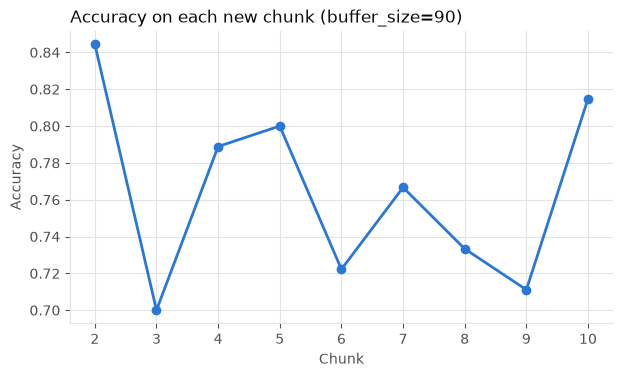

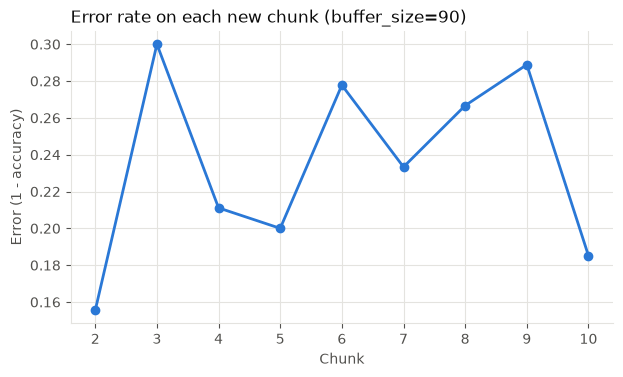

In [64]:
scored_chunks = trainer.metric_history("chunk")
plot_metric_over_time(
    trainer.metric_history("accuracy"),
    "Accuracy on each new chunk (buffer_size=90)",
    "Accuracy",
    x_values=scored_chunks,
)
plot_metric_over_time(
    1 - trainer.metric_history("accuracy"),
    "Error rate on each new chunk (buffer_size=90)",
    "Error (1 - accuracy)",
    x_values=scored_chunks,
);

### 9.2 Several plots in one figure, saved to a file

Passing `ax=` lets you arrange plots side by side. Here we also save the figure; a temporary folder keeps the project directory clean.

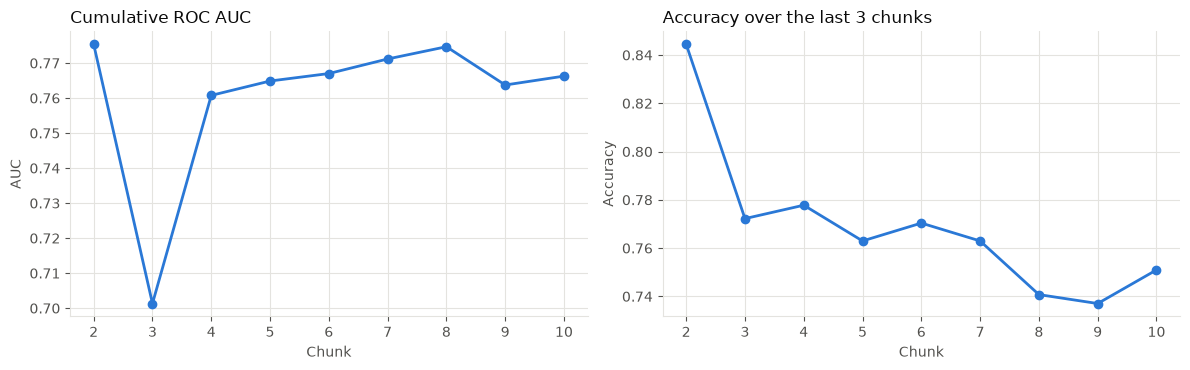

saved: ['stream_dashboard.png']


In [65]:
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8))
plot_metric_over_time(trainer.metric_history("cumulative_auc"), "Cumulative ROC AUC", "AUC",
                      x_values=scored_chunks, ax=left, show=False)
plot_metric_over_time(trainer.metric_history("cumulative_rolling_accuracy"), "Accuracy over the last 3 chunks",
                      "Accuracy", x_values=scored_chunks, ax=right, show=False)
figure.tight_layout()

output_dir = Path(tempfile.mkdtemp())
figure.savefig(output_dir / "stream_dashboard.png", dpi=120)
plt.show()
print("saved:", [path.name for path in output_dir.iterdir()])

### 9.3 Predictions vs ground truth on the latest chunk

Blue dots are the true labels and orange crosses the predictions. A grey line joins every mistake to the correct answer, and the title gives the chunk accuracy.

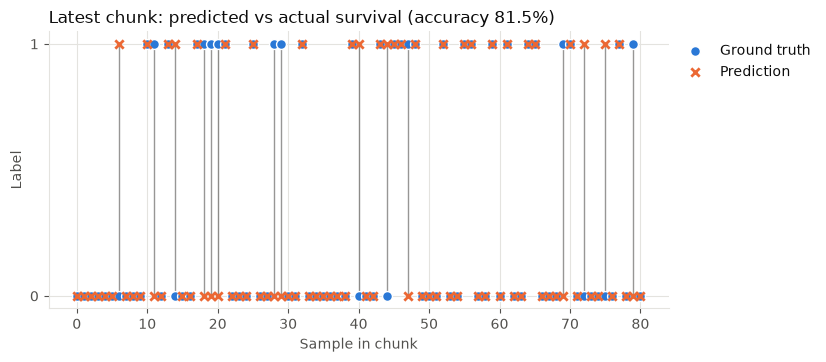

In [66]:
X_latest, y_latest = stream[-1]
plot_predictions_vs_ground_truth(
    y_latest,
    trainer.model.predict(X_latest),
    title="Latest chunk: predicted vs actual survival",
);

## 10. How the buffer size changes the model

The buffer size is a trade-off:

* **small buffer**: retrains often, each time on little data, so the model follows recent data closely but may be unstable;
* **large buffer**: retrains rarely, on more data, so the model is more stable but slower to react.

To compare fairly, both models are scored on **the same chunks** (from chunk 4 on, once the larger buffer has produced its first tree).

In [67]:
BUFFER_SIZES = (90, 270)
trainers = {size: make_trainer(size) for size in BUFFER_SIZES}
FIRST_SCORED = 4

for number, (X_chunk, y_chunk) in enumerate(stream, start=1):
    for model_trainer in trainers.values():
        if number >= FIRST_SCORED:
            model_trainer.score_chunk(X_chunk, y_chunk, chunk_index=number)
        model_trainer.fit_chunk(X_chunk, y_chunk)

for size, model_trainer in trainers.items():
    fitted_tree = model_trainer.model.named_steps["tree"]
    print(f"buffer_size={size:>3}: cumulative accuracy {model_trainer.cumulative_accuracy:.3f}, "
          f"cumulative AUC {model_trainer.logs[-1]['cumulative_auc']:.3f}, "
          f"retrains {fitted_tree.retrain_count_}")

buffer_size= 90: cumulative accuracy 0.762, cumulative AUC 0.777, retrains 9
buffer_size=270: cumulative accuracy 0.804, cumulative AUC 0.837, retrains 3


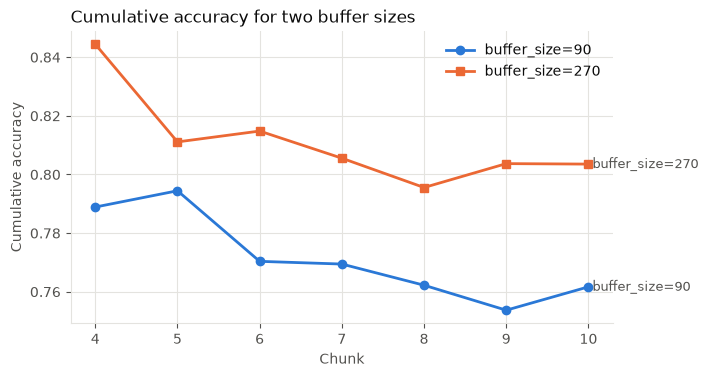

In [68]:
compare_models(
    trainers[90].metric_history("cumulative_accuracy"),
    trainers[270].metric_history("cumulative_accuracy"),
    ["buffer_size=90", "buffer_size=270"],
    title="Cumulative accuracy for two buffer sizes",
    ylabel="Cumulative accuracy",
    x_values=trainers[90].metric_history("chunk"),
);

On this small dataset the larger buffer does better: trees trained on 270 rows are steadier than trees trained on only the last 90. With a larger or drifting stream, the balance can change, which is why the buffer size is worth measuring rather than guessing.

## 11. Benchmarks

### 11.1 Retraining cost vs buffer size

`benchmark_streaming_buffer_sizes` runs the same test-then-train loop for several buffer sizes and also records how long retraining took. It works on numeric features only, so the accuracy here is lower than with the full pipeline.

In [69]:
numeric_X = np.nan_to_num(full_table[:, NUMERIC].astype(float))
results = benchmark_streaming_buffer_sizes(
    numeric_X, all_y, [90, 180, 360], chunk_size=CHUNK_SIZE, max_depth=5
)
print(f"{'buffer':>6} {'accuracy':>9} {'retrains':>9} {'retraining ms':>14}")
for size, result in results.items():
    print(f"{size:>6} {result['accuracy']:>9.3f} {result['retrain_count']:>9} "
          f"{result['retraining_seconds'] * 1000:>14.2f}")

buffer  accuracy  retrains  retraining ms
    90     0.647         9          11.13
   180     0.657         4           6.67
   360     0.657         2           3.91


### 11.2 Toolkit operations vs naive implementations

Each NumCompute operation is timed against the straightforward approach it replaces (Python loops, recomputing from scratch, comparing every pair). Both versions are first checked to give the same answer, so a speed-up is never reported for a wrong result. Timings depend on your machine.

In [70]:
print(format_toolkit_table(benchmark_toolkit(size=20_000, repeats=3)))

| Workload | n | Naive reference (s) | NumCompute (s) | Speed-up |
|---|---:|---:|---:|---:|
| StandardScaler fit+transform (10 features) | 2,000 | 0.001929 | 8.138e-05 | 24x |
| Streaming mean/variance over 500 chunks | 200,000 | 0.04202 | 0.01977 | 2x |
| Confusion matrix (5 classes) | 20,000 | 0.0006607 | 0.0002528 | 3x |
| Decision-tree best split (3 features) | 800 | 0.02155 | 0.0002289 | 94x |
| ROC AUC | 2,000 | 0.01711 | 0.0001185 | 144x |
| Top-10 selection | 20,000 | 0.00156 | 7.158e-05 | 22x |


## 12. Summary

* **Reading:** `iter_csv` streamed the file chunk by chunk.
* **Statistics:** `StreamingStats` matched the batch mean, standard deviation and quantiles exactly without storing the data, and a sliding window showed local changes.
* **Streaming helpers:** `StreamingTopK` and `StreamingRanker` tracked the highest fares and fare percentiles chunk by chunk.
* **Preprocessing:** scalers, the imputer and the encoder all learned with `partial_fit`. The encoder added new categories as new columns without disturbing existing ones.
* **Model:** the decision tree retrained only when its buffer filled, and used the previous tree in between.
* **Pipeline:** an explicit loop trained the whole pipeline with `pipeline.partial_fit` on every chunk, scoring each chunk first and plotting accuracy and error over time.
* **Training loop:** `StreamTrainer` scored each chunk before training on it and logged accuracy, F1, AUC, a rolling window, the confusion matrix, timings and memory.
* **Metrics:** every streaming metric gave the same result as its batch version.
* **Plots:** survival rates by class/sex, age distributions, the latest fitted tree, confusion counts and row-normalised errors, streaming metrics, predictions and buffer comparisons were visualised; reusable `visualise.py` plots also work inline, in subplots and when saved to files.
* **Benchmarks:** the buffer-size benchmark showed the retraining trade-off, and the toolkit benchmark compared NumCompute with naive implementations.

For the API reference, see the project `README.md`. The test suite (`python -m pytest`) checks every component.